# Markov Chains and Tumor Heterogeneity

Nazifa Rahman (cxx5qn) - lab 2 due 11/11

## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,12.879967,12.534007,S-G1
1,1,osimertinib,B,tago-01560,-1.712741,11.650750,P
2,2,osimertinib,A,tago-02253,12.870441,12.998882,S-G1
3,3,osimertinib,A,tago-01478,15.319292,1.937557,S-syn
4,4,osimertinib,A,tago-02626,13.258777,12.765258,S-G1


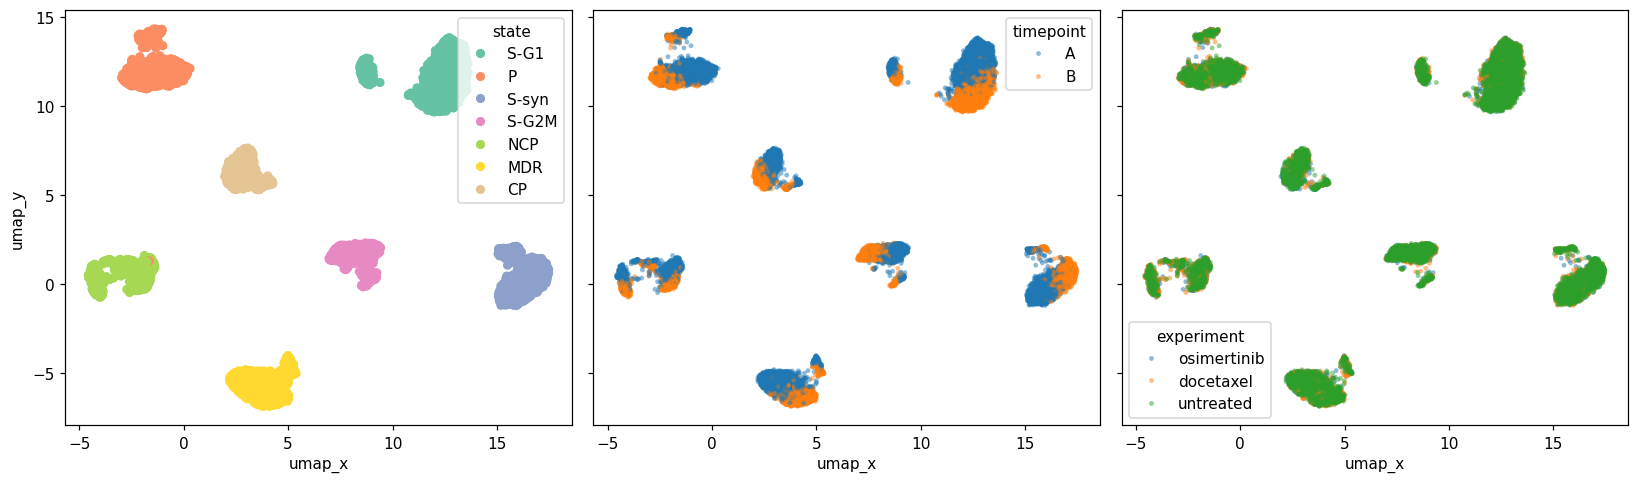

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

In [5]:
cells.head()
cells.shape
cells["experiment"].value_counts()

experiment
untreated      5844
docetaxel      4707
osimertinib    4419
Name: count, dtype: int64

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [6]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [7]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [8]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [9]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [10]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [11]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

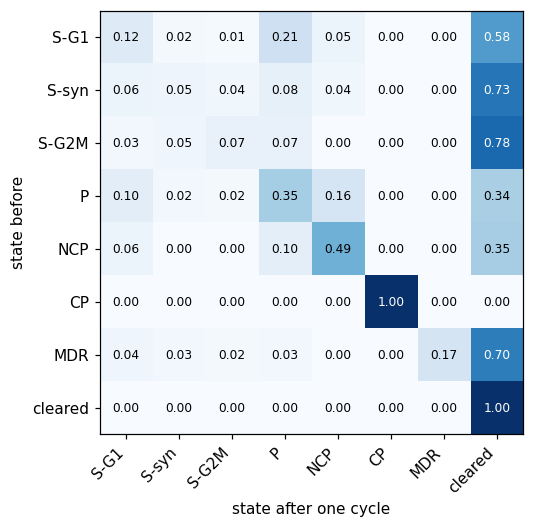

In [12]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

*Answer:* The CP state is approximately absorbing under osimertinib because its probability of remaining in CP is 1.0. This means that cells entering this state remain there rather than transitioning to other states or being cleared. This suggests that CP cells are completely resistant to osimertinib in this simulated dataset. The cleared state is also absorbing because dead cells cannot return to the tumor.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [13]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [14]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [15]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

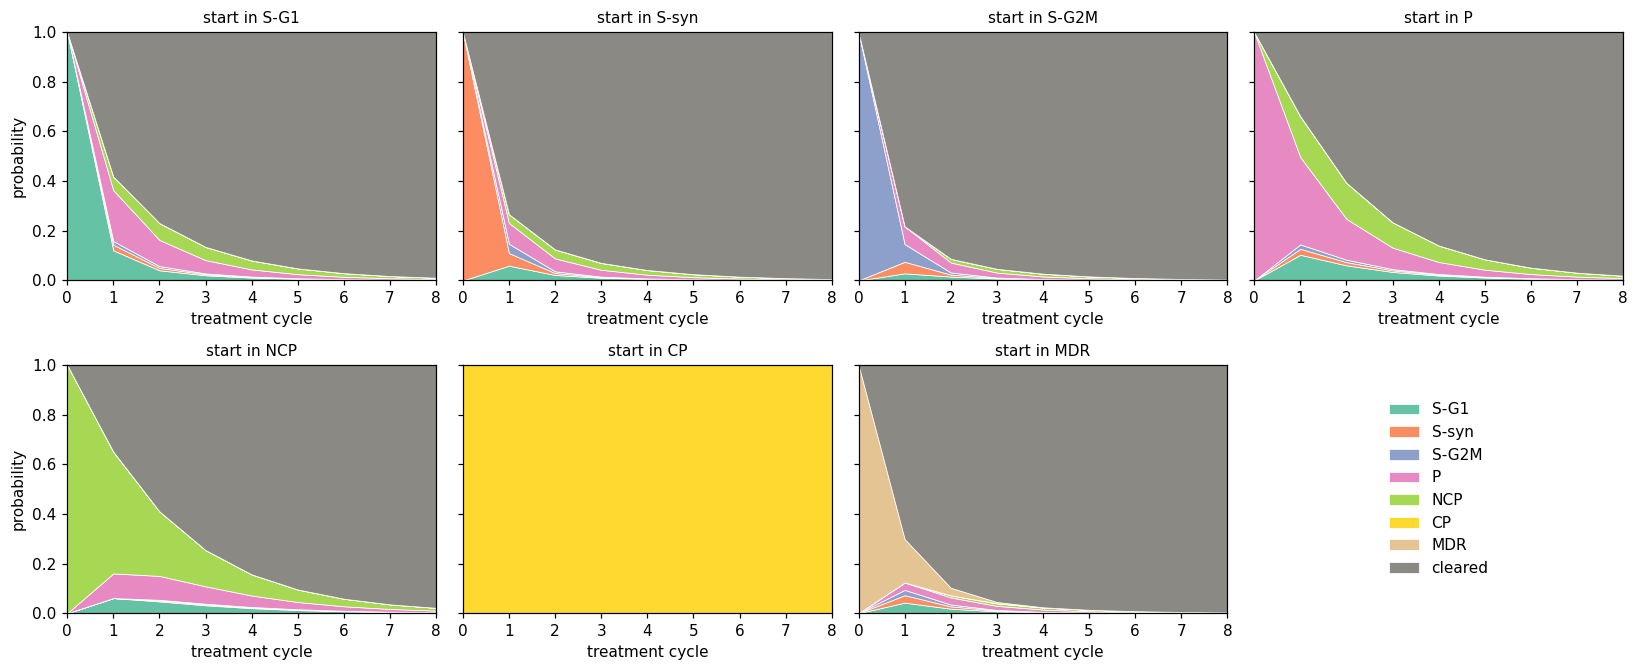

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [16]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



In [17]:
# Build a summary for every starting state

summary = []

for s in STATES:

    traj = evolve(basis(s, P_hat), P_hat, 8)

    alive = 1 - traj[:, OUTCOMES.index("cleared")]

    summary.append({
        "Starting state": s,
        "Alive after 3 cycles": alive[3],
        "Alive after 8 cycles": alive[8],
        "Last cycle >1% alive": np.where(alive > 0.01)[0].max(),
        "Completely cleared?": np.isclose(alive[8], 0)
    })

summary_df = pd.DataFrame(summary)

display(summary_df.round(4))

,Starting state,Alive after 3 cycles,Alive after 8 cycles,Last cycle >1% alive,Completely cleared?
0,S-G1,0.1352,0.0108,8,False
1,S-syn,0.0707,0.0056,6,False
2,S-G2M,0.0467,0.0036,5,False
3,P,0.2344,0.0190,8,False
4,NCP,0.2543,0.0216,8,False
5,CP,1.0000,1.0000,8,False
6,MDR,0.0451,0.0029,5,False


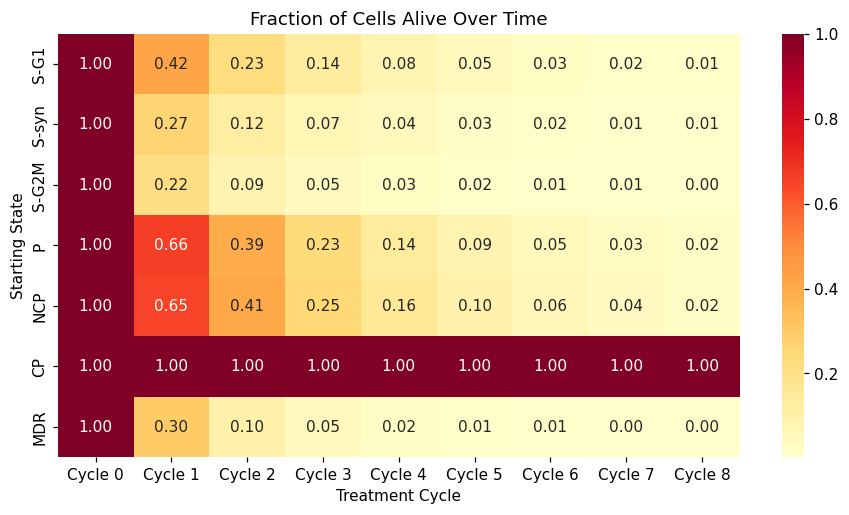

In [18]:
# Heatmap showing survival through all cycles

survival = {}

for s in STATES:
    traj = evolve(basis(s, P_hat), P_hat, 8)
    survival[s] = 1 - traj[:, OUTCOMES.index("cleared")]

survival_df = pd.DataFrame(
    survival,
    index=[f"Cycle {i}" for i in range(9)]
)

plt.figure(figsize=(10,5))

sns.heatmap(
    survival_df.T,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)

plt.title("Fraction of Cells Alive Over Time")
plt.xlabel("Treatment Cycle")
plt.ylabel("Starting State")
plt.show()

In [19]:
alive_after_3 = {}

for s in STATES:
    traj = evolve(basis(s, P_hat), P_hat, 8)
    alive_after_3[s] = 1 - traj[3, OUTCOMES.index("cleared")]

pd.Series(alive_after_3).sort_values(ascending=False)

CP       1.000000
NCP      0.254336
P        0.234360
S-G1     0.135156
S-syn    0.070709
S-G2M    0.046717
MDR      0.045077
dtype: float64

Answer: 

**1. Which starting states does osimertinib completely eliminate (all probability ends in cleared)? Which ones survive?**

The only state that clearly survives indefinitely is **CP**, which remains at 100% survival after all eight treatment cycles. All other starting states (S-G1, S-syn, S-G2M, P, NCP, and MDR) show survival probabilities that approach zero over time, indicating they are progressively cleared by treatment. Although small fractions remain after eight cycles (0.29%-2.16%), these states continue trending toward the absorbing cleared state, whereas CP persists because it is an absorbing and drug-resistant state.

**2. Of the states that can be cleared, which tumor lasts the longest?**

Among the states that can eventually be cleared, **NCP** lasts the longest. After eight treatment cycles, NCP has the highest remaining survival probability (2.16%), followed by P (1.90%). This suggests that persister-like states are more difficult to eliminate than the proliferative states.

**3. Which starting state sticks around for the most cycles of drug?**

**CP** sticks around for the most cycles of treatment. Its survival probability remains 1.0 throughout all eight cycles because cells in CP never transition to another state or to the cleared state. As an absorbing state, CP is essentially unaffected by osimertinib.

**4. Which starting state results in the highest proportion of alive cells after three cycles?**

**CP** results in the highest proportion of alive cells after three cycles, with 100% of cells surviving. Excluding the completely resistant CP state, **NCP** has the highest survival after three cycles (25.43%), followed by **P** (23.44%). This further supports the conclusion that persister states are more tolerant of osimertinib treatment than the other cell states.

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

In [20]:
# Select all cells at timepoint A across all experiments
time_A = cells[cells["timepoint"] == "A"]

# Calculate the proportion of cells in each state
state_counts = time_A["state"].value_counts()

pi_mix = state_counts.reindex(STATES, fill_value=0).values
pi_mix = pi_mix / pi_mix.sum()

# Add zero probability for the cleared state
pi_mix = np.append(pi_mix, 0)

print(pd.Series(pi_mix, index=OUTCOMES).round(4))

S-G1       0.2470
S-syn      0.1483
S-G2M      0.0994
P          0.1526
NCP        0.1024
CP         0.0972
MDR        0.1530
cleared    0.0000
dtype: float64


In [21]:
# Evolve the mixed tumor under osimertinib

traj_mix = evolve(pi_mix, P_hat, 8)

# Convert to dataframe for easier viewing
mix_df = pd.DataFrame(traj_mix, columns=OUTCOMES)

display(mix_df.round(4))

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.2470,0.1483,0.0994,0.1526,0.1024,0.0972,0.1530,0.0000
1,0.0701,0.0260,0.0222,0.1386,0.0941,0.0972,0.0268,0.5251
2,0.0319,0.0081,0.0066,0.0770,0.0737,0.0972,0.0047,0.7008
3,0.0172,0.0034,0.0027,0.0422,0.0509,0.0972,0.0008,0.7856
4,0.0099,0.0017,0.0013,0.0239,0.0330,0.0972,0.0001,0.8328
5,0.0058,0.0010,0.0007,0.0140,0.0207,0.0972,0.0000,0.8606
6,0.0035,0.0006,0.0004,0.0083,0.0128,0.0972,0.0000,0.8772
7,0.0021,0.0003,0.0002,0.0050,0.0079,0.0972,0.0000,0.8873
8,0.0013,0.0002,0.0001,0.0030,0.0048,0.0972,0.0000,0.8934


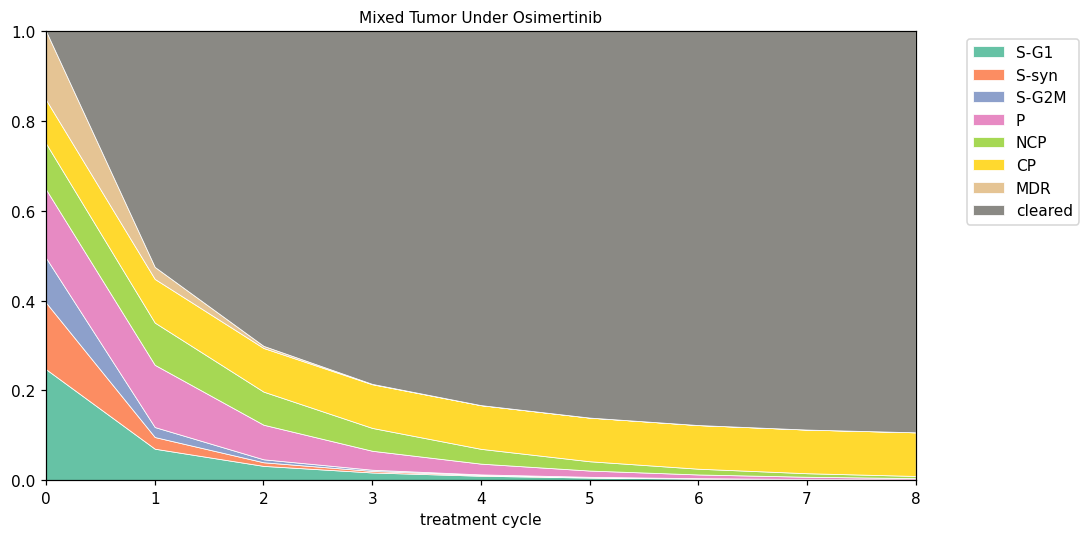

In [22]:
fig, ax = plt.subplots(figsize=(10,5))

plot_trajectory(
    traj_mix,
    ax,
    "Mixed Tumor Under Osimertinib"
)

ax.legend(
    OUTCOMES,
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

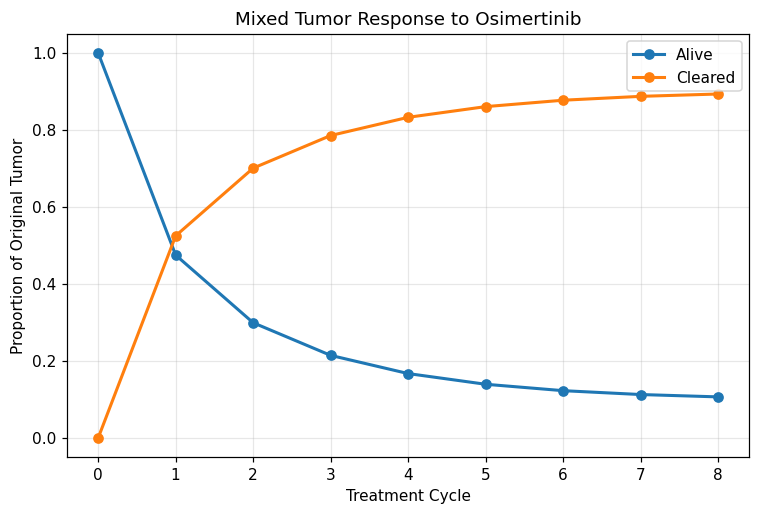

In [23]:
alive = 1 - traj_mix[:, OUTCOMES.index("cleared")]
cleared = traj_mix[:, OUTCOMES.index("cleared")]

plt.figure(figsize=(8,5))

plt.plot(range(9), alive,
         marker="o",
         linewidth=2,
         label="Alive")

plt.plot(range(9), cleared,
         marker="o",
         linewidth=2,
         label="Cleared")

plt.xlabel("Treatment Cycle")
plt.ylabel("Proportion of Original Tumor")
plt.title("Mixed Tumor Response to Osimertinib")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

9.72% of the original tumor is CP, this is important because CP is completely resistant to osimertinib in the transition matrix.

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

- After eight cycles of osimertinib, approximately 89.34% of the original tumor population is cleared. However, approximately 10.66% remains alive, with CP representing the largest surviving population. CP dominates the remaining tumor because it is an absorbing state under osimertinib, meaning cells that enter CP remain there with probability 1 and cannot transition to other states or be cleared.
 
- These cells will not be eliminated by additional osimertinib treatment. The long-run behavior follows directly from the transition matrix: because CP and cleared are absorbing states, probability gradually accumulates in one of these two outcomes. As sensitive states are eliminated, the remaining tumor becomes increasingly enriched for CP cells. Therefore, repeated osimertinib treatment alone cannot completely eliminate this mixed tumor because probability accumulates in the absorbing CP state rather than flowing entirely into the cleared state.

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [24]:
def build_transition_matrix(experiment):

    # Filter the dataset for the selected experiment
    data = cells[cells["experiment"] == experiment]

    # Separate timepoints A and B
    at_A = data[data["timepoint"] == "A"][["lineage_tag", "state"]]
    at_B = data[data["timepoint"] == "B"][["lineage_tag", "state"]]

    # Match cells using their lineage tags
    pairs = pd.merge(
        at_A,
        at_B,
        on="lineage_tag",
        how="left",
        suffixes=("_A", "_B")
    )

    # Mark cells missing at timepoint B as cleared
    pairs["state_B"] = pairs["state_B"].fillna("cleared")

    # Count transitions between states
    counts = pd.crosstab(
        pairs["state_A"],
        pairs["state_B"]
    ).reindex(
        index=STATES,
        columns=OUTCOMES,
        fill_value=0
    )

    # Normalize counts to obtain transition probabilities
    P = counts.div(counts.sum(axis=1), axis=0)

    # Add the absorbing cleared state
    P.loc["cleared"] = 0
    P.loc["cleared", "cleared"] = 1

    return P

In [25]:
# Keep these as 8x8 numpy arrays (with the cleared row)
P_osi = P_hat.to_numpy()

# Build transition matrices for each experiment
P_doc = build_transition_matrix("docetaxel").to_numpy()

P_holiday = build_transition_matrix("untreated").to_numpy()

print("Osimertinib shape:", P_osi.shape)
print("Docetaxel shape:", P_doc.shape)
print("Drug holiday shape:", P_holiday.shape)

Osimertinib shape: (8, 8)
Docetaxel shape: (8, 8)
Drug holiday shape: (8, 8)


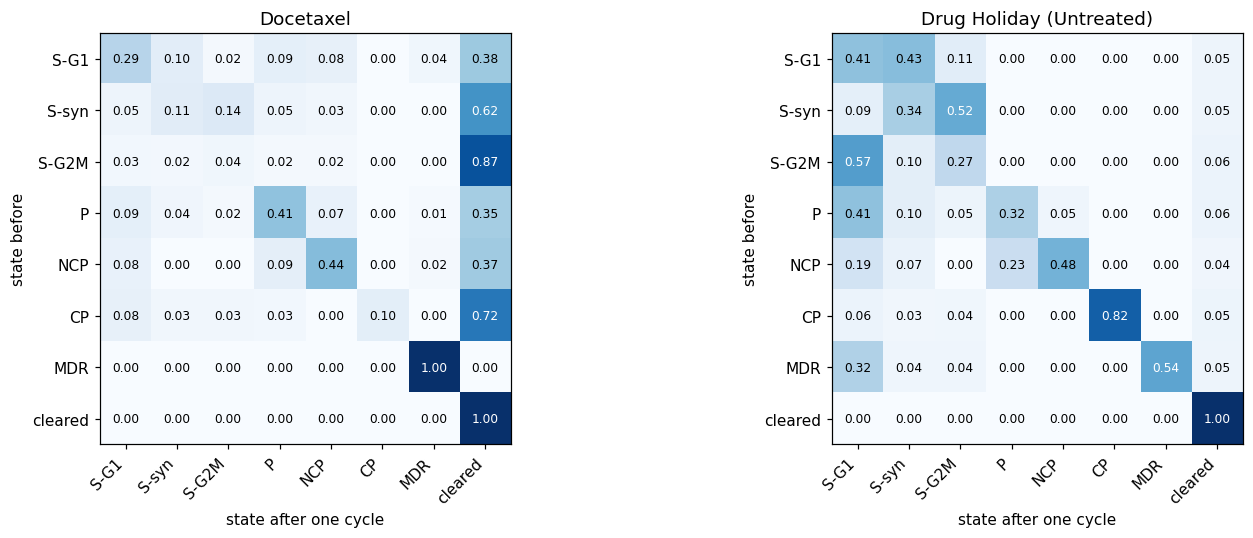

In [26]:
#Plot the transition matrices for docetaxel and the drug holiday.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

show_matrix(
    pd.DataFrame(P_doc, index=OUTCOMES, columns=OUTCOMES),
    "Docetaxel",
    axes[0]
)

show_matrix(
    pd.DataFrame(P_holiday, index=OUTCOMES, columns=OUTCOMES),
    "Drug Holiday (Untreated)",
    axes[1]
)

plt.tight_layout()
plt.show()


In [27]:
# Simulate the evolution of pi_mix under docetaxel 

traj_doc = evolve(pi_mix, P_doc, 8)

# Display the distribution after each treatment cycle
doc_results = pd.DataFrame(traj_doc, columns=OUTCOMES)

display(doc_results.round(3))


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


**1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?**
- The transition matrices show that each treatment affects tumor cell states differently. Under osimertinib, CP is an absorbing state, meaning cells in CP remain in that state with probability 1. Under docetaxel, MDR is an absorbing state, meaning MDR cells are completely resistant to treatment. Under the drug holiday, no living cell state is fully absorbing, although CP (0.82) and MDR (0.54) have relatively high probabilities of remaining in their respective states. The cleared state is absorbing under all three conditions. Compared to osimertinib, docetaxel shifts probability toward MDR while osimertinib shifts probability toward CP. Under the drug holiday, cells continue transitioning among states, so untreated tumors remain more heterogeneous than tumors exposed to either drug.

 
**2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?**
- The proportion of cleared cells increases with each treatment cycle, while MDR becomes an increasingly large fraction of the surviving tumor population. After eight cycles, approximately 81% of the original tumor is cleared, while about 19% remains alive. MDR becomes the dominant surviving state because it is absorbing under docetaxel and cannot be cleared by further treatment. This suggests that docetaxel selects for MDR cells in the same way that osimertinib selects for CP cells.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [28]:
# COMPARE DRUG TREATMENT SCHEDULES

# 1. Eight cycles of osimertinib
osi_8 = pi_mix.copy()

for _ in range(8):
    osi_8 = osi_8 @ P_osi

# 2. Eight cycles of docetaxel
doc_8 = pi_mix.copy()

for _ in range(8):
    doc_8 = doc_8 @ P_doc

# 3. Eight alternating cycles: Osimertinib then Docetaxel
# Four pairs = eight total treatment cycles
OD_8 = pi_mix.copy()

for _ in range(4):
    OD_8 = OD_8 @ P_osi @ P_doc

# 4. Eight alternating cycles: Docetaxel then Osimertinib
DO_8 = pi_mix.copy()

for _ in range(4):
    DO_8 = DO_8 @ P_doc @ P_osi

# Compare final tumor distributions
schedule_results = pd.DataFrame({
    "Osimertinib": osi_8,
    "Docetaxel": doc_8,
    "Alternating OD": OD_8,
    "Alternating DO": DO_8
}, index=OUTCOMES)

print("Final tumor distributions after 8 cycles:")
display(schedule_results.round(4))

# Calculate the percentage of the original tumor remaining alive
alive_results = (1 - schedule_results.loc["cleared"]) * 100

print("Percentage of tumor cells remaining alive:")
display(alive_results.round(2))


Final tumor distributions after 8 cycles:


,Osimertinib,Docetaxel,Alternating OD,Alternating DO
S-G1,0.0013,0.0015,0.0016,0.0014
S-syn,0.0002,0.0006,0.0005,0.0003
S-G2M,0.0001,0.0003,0.0003,0.0002
P,0.0030,0.0024,0.0030,0.0031
NCP,0.0048,0.0023,0.0033,0.0038
CP,0.0972,0.0000,0.0000,0.0000
MDR,0.0000,0.1826,0.0007,0.0003
cleared,0.8934,0.8104,0.9906,0.9908


Percentage of tumor cells remaining alive:


Osimertinib       10.66
Docetaxel         18.96
Alternating OD     0.94
Alternating DO     0.92
Name: cleared, dtype: float64

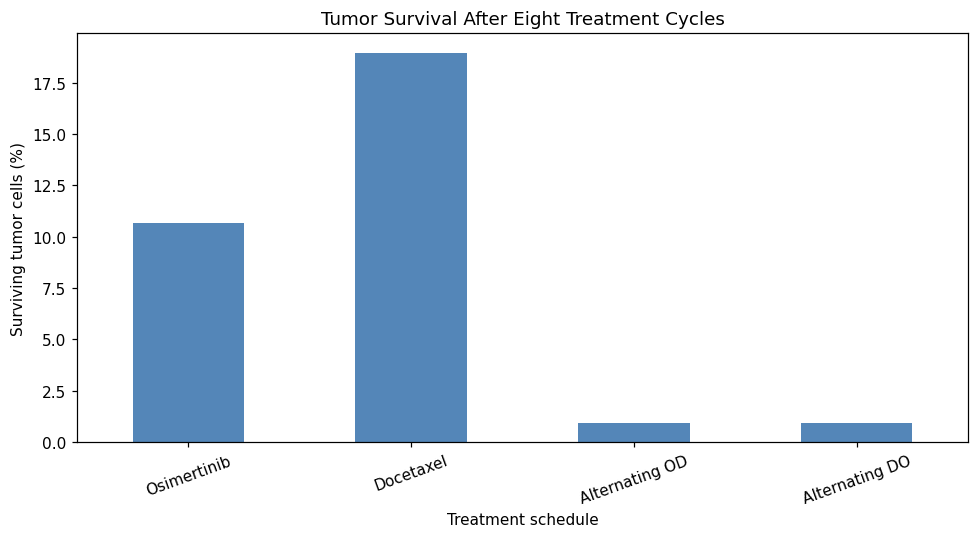

In [29]:

# Plot surviving tumor populations under each treatment schedule

alive_results.plot(
    kind="bar",
    figsize=(9, 5),
    color="#5486B8"
)

plt.ylabel("Surviving tumor cells (%)")
plt.xlabel("Treatment schedule")
plt.title("Tumor Survival After Eight Treatment Cycles")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [30]:

# Compare the two alternating treatment schedules

print("Alternating OD: surviving cells =", round(alive_results["Alternating OD"], 3), "%")
print("Alternating DO: surviving cells =", round(alive_results["Alternating DO"], 3), "%")

difference = abs(
    alive_results["Alternating OD"] -
    alive_results["Alternating DO"]
)

print("Difference between schedules:", round(difference, 4), "percentage points")


Alternating OD: surviving cells = 0.941 %
Alternating DO: surviving cells = 0.916 %
Difference between schedules: 0.0249 percentage points


**1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib to an alternating drug schedule.**
- After eight treatment cycles, **osimertinib** leaves approximately **10.66%** of tumor cells alive, while **docetaxel** leaves **18.96%** alive. In contrast, the alternating treatment schedules are substantially more effective. The **Osimertinib → Docetaxel (OD)** schedule leaves only **0.94%** of cells alive, while the **Docetaxel → Osimertinib (DO)** schedule leaves only **0.92%** alive. Both alternating schedules achieve approximately **99% tumor clearance**, greatly outperforming either drug alone. These results suggest that alternating therapies target both CP and MDR resistant populations, preventing either resistant state from dominating the tumor.

**2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?**
- For this mixed tumor, the starting drug makes very little difference. The OD schedule results in **0.94%** surviving cells, while the DO schedule results in **0.92%** surviving cells, a difference of only **0.02 percentage points**. Although matrix multiplication is generally not commutative, both treatment orders produce nearly identical outcomes for this tumor composition. Therefore, either alternating schedule is highly effective.

**3. In what situation would a drug holiday help clear the tumor?**
- A drug holiday may help when treatment has pushed cells into resistant or persister-like states. Under the drug holiday transition matrix, no living state is completely absorbing, meaning cells can continue transitioning between states rather than remaining permanently trapped in a resistant population. As a result, a drug holiday could allow some resistant cells to transition back into more drug-sensitive states before treatment resumes. This strategy would likely be most beneficial for tumors enriched in persister states (P and NCP), which retain the ability to switch states when drug pressure is removed.

**4. Treatment Prescription**

| Tumor Composition | Recommended Treatment | Reasoning |
|-------------------|----------------------|-----------|
| Mostly CP cells | Docetaxel (6-8 cycles) | CP is resistant to osimertinib but can be eliminated by docetaxel. |
| Mostly MDR cells | Osimertinib (6-8 cycles) | MDR is resistant to docetaxel but is effectively cleared by osimertinib. |
| Mostly proliferative states (S-G1, S-syn, S-G2M) | Either drug (4-8 cycles) | Both drugs effectively eliminate these sensitive cell populations. |
| High P or NCP populations | Alternating therapy | Persister states survive longer and can contribute to the development of resistance. |
| Mixed tumors containing CP and MDR | Alternating OD or DO schedule (8 cycles) | Produces the highest tumor clearance (~99%) and prevents either resistant population from dominating. |

Overall, the alternating treatment schedules provide the best outcomes for heterogeneous tumors. While osimertinib alone leaves **10.66%** of cells alive and docetaxel leaves **18.96%** alive, alternating therapy reduces survival to **less than 1%**. Therefore, alternating treatment is the preferred strategy for mixed tumors containing multiple resistant cell populations.




## 6 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [31]:
rng = np.random.default_rng(100)

In [32]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [33]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

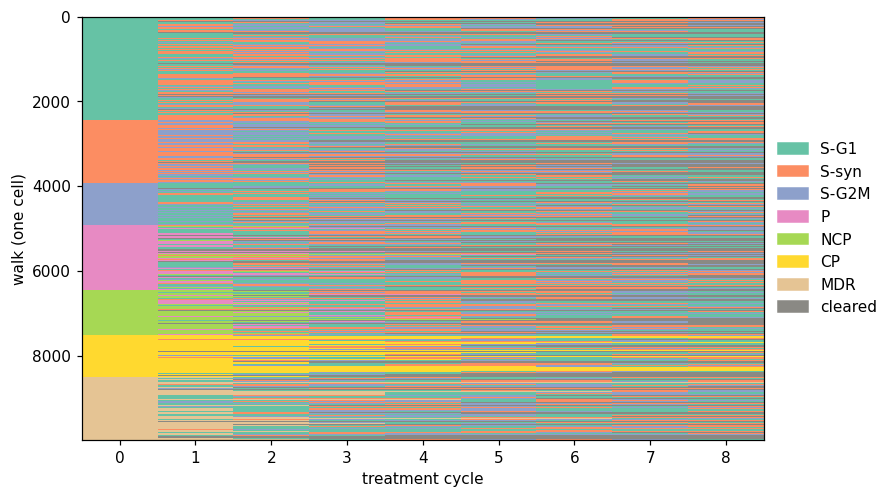

In [34]:
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [35]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

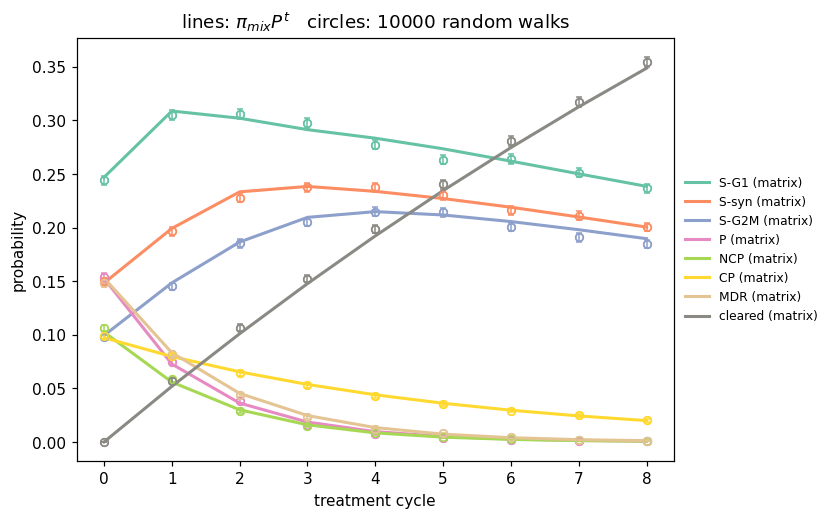

In [36]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

Answer: 

- Increasing N_WALKS from 100 to 10,000 substantially reduces the gap between the circles and the lines. The circles represent empirical frequencies from the simulations, while the lines represent the exact probabilities obtained from the transition matrix. With more simulated cells, the sampling error decreases and the standard error becomes smaller, resulting in tighter error bars and closer agreement with the theoretical curves. This is expected from the Law of Large Numbers, which states that sample proportions converge to the true probabilities as the sample size increases.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [37]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

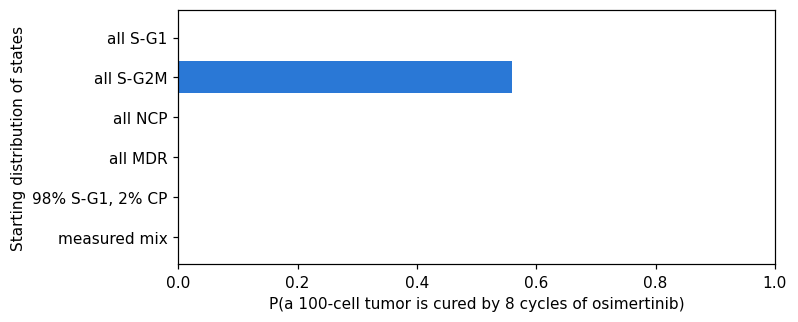

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.00,6.915,0.0
all S-G2M,0.56,0.575,0.0
all NCP,0.00,6.615,0.0
all MDR,0.00,100.000,0.0
"98% S-G1, 2% CP",0.00,6.950,0.0
measured mix,0.00,19.250,0.0


In [38]:
N_CELLS, N_TUMORS = 100, 200
# P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8 # rerunning for docetaxel instead of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

Answer: 

- When the tumor-clearing simulation is repeated using docetaxel instead of osimertinib, cure probabilities vary substantially depending on the starting cell population. Tumors composed entirely of S-G2M cells are the easiest to eliminate, with a cure probability of approximately 56% and fewer than one surviving cell on average after eight treatment cycles.
 
- In contrast, tumors containing MDR cells are essentially impossible to cure with docetaxel. The all-MDR tumors have a cure probability of 0 and an average of 100 surviving cells, indicating that MDR cells are completely resistant to docetaxel. Similarly, the measured mixed tumor and the other starting populations all have cure probabilities of 0, with surviving cells remaining after treatment.
 
- These results differ from the osimertinib simulations because docetaxel selects for MDR cells rather than CP cells. While osimertinib leaves CP cells as the dominant survivors, docetaxel leaves MDR cells as the resistant population. Therefore, the effectiveness of treatment depends strongly on the tumor's initial composition and which resistant state is favored by a particular drug.



## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [39]:
# write a function that runs 1000 random walks and saves them

# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally

# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test



In [40]:
# SECTION 6: Investigating the Persister State

rng = np.random.default_rng(5030)

# indices of persister states
P_IDX = OUTCOMES.index("P")
NCP_IDX = OUTCOMES.index("NCP")

PERSISTERS = {P_IDX, NCP_IDX}


# Does a cell become PR?
def becomes_PR(path):
    """
    Returns True if a cell spends
    3 or more consecutive cycles
    in P and/or NCP states.
    """

    streak = 0

    for state in path:

        if state in PERSISTERS:
            streak += 1

            if streak >= 3:
                return True

        else:
            streak = 0

    return False





In [41]:
# Simulate one tumor
def simulate_PR_tumor(pi0, P, n_cells=1000,
                      n_cycles=8, rng=None):

    if rng is None:
        rng = np.random.default_rng()

    starts = rng.choice(
        len(pi0),
        size=n_cells,
        p=pi0
    )

    pr_count = 0

    for s0 in starts:

        path = random_walk(
            int(s0),
            P,
            n_cycles,
            rng
        )

        if becomes_PR(path):
            pr_count += 1

    return pr_count / n_cells



In [42]:

# Evaluate one treatment strategy
def evaluate_strategy(pi0,
                      P,
                      n_cycles,
                      n_tumors=100,
                      n_cells=1000,
                      threshold=0.10):

    pr_fractions = []

    for _ in range(n_tumors):

        frac_PR = simulate_PR_tumor(
            pi0,
            P,
            n_cells=n_cells,
            n_cycles=n_cycles,
            rng=rng
        )

        pr_fractions.append(frac_PR)

    pr_fractions = np.array(pr_fractions)

    mean_pr = pr_fractions.mean()

    sem_pr = (
        pr_fractions.std(ddof=1)
        / np.sqrt(len(pr_fractions))
    )

    ci_low = mean_pr - 1.96 * sem_pr
    ci_high = mean_pr + 1.96 * sem_pr

    pct_above_10 = (
        np.mean(pr_fractions > threshold)
        * 100
    )

    return {
        "Mean PR": mean_pr,
        "SEM": sem_pr,
        "95% CI Low": ci_low,
        "95% CI High": ci_high,
        "% Tumors >10% PR": pct_above_10
    }


In [43]:


# Treatment matrices
P_OD = P_osi @ P_doc          # alternating O->D
P_DH = P_doc @ P_holiday      # docetaxel + holiday


# Compare strategies across cycle lengths
cycle_lengths = [2, 4, 6, 8, 10, 12]

results = []

for n_cycles in cycle_lengths:

    treatments = {
        "Osimertinib": P_osi,
        "Docetaxel": P_doc,
        "Alternating OD": P_OD,
        "Docetaxel + Holiday": P_DH
    }

    for treatment, P in treatments.items():

        out = evaluate_strategy(
            pi_mix,
            P,
            n_cycles=n_cycles,
            n_tumors=100,
            n_cells=1000
        )

        results.append({
            "Treatment": treatment,
            "Cycles": n_cycles,
            **out
        })


results_df = pd.DataFrame(results)

display(results_df.round(4))



,Treatment,Cycles,Mean PR,SEM,95% CI Low,95% CI High,% Tumors >10% PR
0,Osimertinib,2,0.0771,0.0008,0.0755,0.0788,0.0
1,Docetaxel,2,0.0642,0.0007,0.0627,0.0656,0.0
2,Alternating OD,2,0.0220,0.0005,0.0211,0.0229,0.0
3,Docetaxel + Holiday,2,0.0171,0.0004,0.0163,0.0179,0.0
4,Osimertinib,4,0.1126,0.0011,0.1104,0.1148,85.0
5,Docetaxel,4,0.0851,0.0009,0.0834,0.0868,6.0
6,Alternating OD,4,0.0285,0.0005,0.0275,0.0295,0.0
7,Docetaxel + Holiday,4,0.0210,0.0005,0.0201,0.0219,0.0
8,Osimertinib,6,0.1141,0.0010,0.1122,0.1160,91.0
9,Docetaxel,6,0.0911,0.0010,0.0892,0.0930,17.0


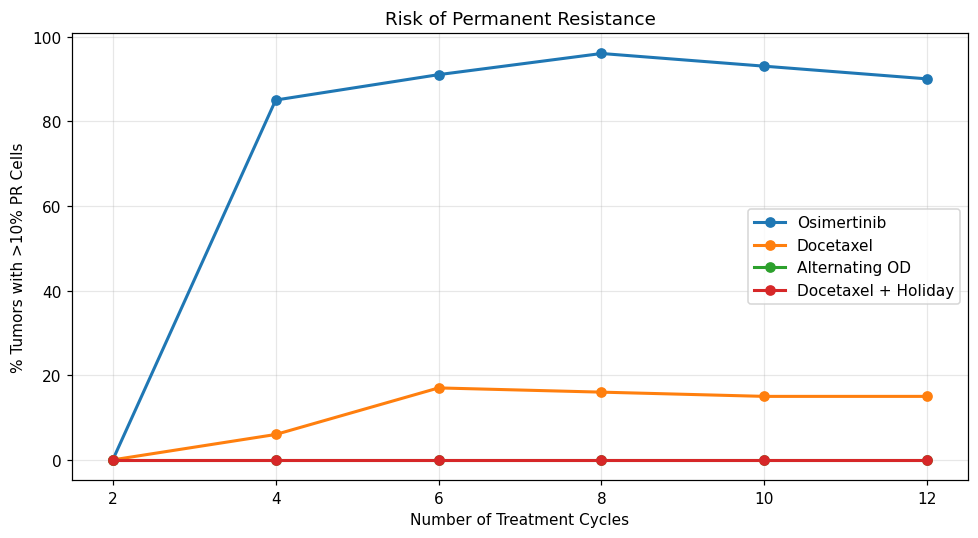

In [44]:

# Plot percent of tumors >10% PR
plt.figure(figsize=(9,5))

for treatment in results_df["Treatment"].unique():

    subset = results_df[
        results_df["Treatment"] == treatment
    ]

    plt.plot(
        subset["Cycles"],
        subset["% Tumors >10% PR"],
        marker="o",
        linewidth=2,
        label=treatment
    )

plt.xlabel("Number of Treatment Cycles")
plt.ylabel("% Tumors with >10% PR Cells")
plt.title("Risk of Permanent Resistance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

Answer: The percentage of tumors with more than 10% permanently resistant (PR) cells depends strongly on the treatment strategy.

- Under **osimertinib alone**, no tumors exceed the 10% threshold after 2 cycles. However, after 4 cycles, 85% of tumors exceed the threshold, increasing to 91% after 6 cycles and reaching a maximum of 96% after 8 cycles. The percentage remains very high at 93% and 90% after 10 and 12 cycles, respectively. This indicates that osimertinib strongly promotes the accumulation of cells that remain in persister states long enough to become permanently resistant.

- Under **docetaxel alone**, no tumors exceed the threshold after 2 cycles, and only 6% exceed it after 4 cycles. This increases to 17% after 6 cycles and remains between 15% and 16% through 12 cycles. Docetaxel therefore produces substantially fewer permanently resistant tumors than osimertinib.

- Under the **alternating OD (osimertinib → docetaxel)** schedule, 0% of tumors exceed the 10% threshold at all cycle lengths examined. The mean PR fraction remains below 3% throughout the simulation, indicating that alternating treatment effectively prevents the buildup of permanently resistant cells.

- Similarly, **docetaxel followed by a drug holiday** results in 0% of tumors exceeding the 10% threshold across all cycle lengths. The mean PR fraction remains near 2%, suggesting that drug holidays reduce the amount of time cells spend continuously in persister states.

Overall, the risk of permanent resistance generally increases as the number of treatment cycles increases because cells have more opportunities to remain in P or NCP states for three or more consecutive cycles. Among all strategies tested, **osimertinib alone produced the highest risk of permanent resistance**, while **alternating therapy and docetaxel with a drug holiday were the most effective at preventing permanently resistant cells from emerging.**